# Search-01 : Espaces d'etats et formulation de problemes

**Navigation** : [Index](../README.md) | [Suivant >>](Search-02-Uninformed.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Définir** formellement un problème de recherche comme un 5-tuple (S, s0, A, T, G)
2. **Modeliser** des problemes concrets (aspirateur, taquin, itineraire) comme des espaces d'etats
3. **Implementer** en Python les composants d'un problème de recherche (etats, actions, transitions)
4. **Analyser** les proprietes d'un espace d'etats (taille, observabilite, determinisme)

### Prerequis
- Python 3.10+ (bases du langage)
- Structures de données de base (listes, dictionnaires, ensembles)
- Notions elementaires de théorie des graphes

### Duree estimee : 40 minutes

## 1. Introduction

### Qu'est-ce qu'un problème de recherche ?

Un **problème de recherche** consiste a trouver une sequence d'actions menant d'une situation initiale a une situation desiree. Ce cadre general permet de modeliser un grand nombre de problemes :

| Domaine | Problème | Etat | Action |
|---------|----------|------|--------|
| Navigation | GPS, itineraire | Position actuelle | Se deplacer vers une ville voisine |
| Jeux | Taquin, echecs | Configuration du plateau | Deplacer une piece |
| Planification | Robot, logistique | Configuration du monde | Executer une action |
| Optimisation | Emploi du temps | Affectation partielle | Assigner une ressource |

### Pourquoi formaliser ?

La formalisation d'un problème en **espace d'etats** offre plusieurs avantages :
- **Generalite** : un seul algorithme (BFS, A*, etc.) peut resoudre de nombreux problemes différents
- **Rigueur** : la solution est un chemin verifiable dans un graphe bien défini
- **Analyse** : on peut raisonner sur la completude, l'optimalite et la complexite

> **Reference** : Ce notebook suit le chapitre 3 de *Artificial Intelligence: A Modern Approach* (Russell & Norvig).


> *Ancres savantes -- Newell, A. & Simon, H.A. (1961), GPS, A Program That Simulates Human Thought, in R. Gunbaum & E. Paul (eds.), Thinking Machines, Basic Books (formalisation pionnière du state-space search : état initial, opérateurs, état-but) ; Amarel, S. (1968), On Representations of Problems of Reasoning About Actions, Machine Intelligence 3:131-171 (représentation d'état et importance de la formulation pour la complexité de recherche) ; Russell, S. & Norvig, P. (2020), Artificial Intelligence: A Modern Approach (4th ed.), Pearson (cadre formel du problème de recherche : états, actions, coût, heuristique, chapitre 3).*

In [1]:
# Imports
import sys
sys.path.insert(0, '..')

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import deque
from typing import Any, List, Set, Tuple, Optional, Callable
from copy import deepcopy

print("Environnement pret.")

Environnement pret.


## 2. Formalisation d'un problème de recherche

### Le 5-tuple $(S, s_0, A, T, G)$

Un problème de recherche se définit formellement par cinq composants :

| Composant | Notation | Description |
|-----------|----------|-------------|
| **Espace d'etats** | $S$ | Ensemble de toutes les configurations possibles |
| **Etat initial** | $s_0 \in S$ | Configuration de depart |
| **Actions** | $A(s)$ | Ensemble des actions applicables dans l'etat $s$ |
| **Fonction de transition** | $T(s, a) \to s'$ | Etat resultant de l'action $a$ dans l'etat $s$ |
| **Test de but** | $G(s) \to \{vrai, faux\}$ | Determine si $s$ est un etat objectif |

On ajoute souvent une **fonction de cout** $c(s, a, s') \geq 0$ qui associe un cout a chaque transition.

### Solutions

- Une **solution** est un chemin $(s_0, a_1, s_1, a_2, ..., a_n, s_n)$ tel que $G(s_n) = vrai$
- Le **cout d'une solution** est $\sum_{i=1}^{n} c(s_{i-1}, a_i, s_i)$
- Une **solution optimale** est une solution de cout minimal

### Classe abstraite

Nous allons d'abord définir une classe abstraite `SearchProblem` qui capture cette formalisation. Chaque problème concret heritera de cette classe.

In [2]:
class SearchProblem:
    """
    Classe abstraite representant un probleme de recherche.
    
    Correspond au 5-tuple (S, s0, A, T, G) avec cout optionnel.
    """
    
    def initial_state(self):
        """Retourne l'etat initial s0."""
        pass  # TODO etudiant : implementer pour chaque sous-classe
    
    def actions(self, state) -> List:
        """Retourne la liste des actions applicables dans l'etat donne."""
        pass  # TODO etudiant : implementer pour chaque sous-classe
    
    def transition(self, state, action):
        """Retourne l'etat resultant de l'application de l'action."""
        pass  # TODO etudiant : implementer pour chaque sous-classe
    
    def is_goal(self, state) -> bool:
        """Teste si l'etat est un etat objectif."""
        pass  # TODO etudiant : implementer pour chaque sous-classe
    
    def cost(self, state, action, next_state) -> float:
        """Cout de la transition (defaut = 1 pour chaque action)."""
        return 1.0
    
    def state_space_size(self) -> Optional[int]:
        """Taille de l'espace d'etats (si calculable)."""
        return None
    
    def __repr__(self):
        size = self.state_space_size()
        size_str = f", |S|={size}" if size else ""
        return f"SearchProblem({self.__class__.__name__}{size_str})"


print("Classe SearchProblem definie.")
print("Methodes : initial_state(), actions(s), transition(s,a), is_goal(s), cost(s,a,s')")

Classe SearchProblem definie.
Methodes : initial_state(), actions(s), transition(s,a), is_goal(s), cost(s,a,s')


## 3. Exemple 1 : Le monde de l'aspirateur

### Description

Le **monde de l'aspirateur** (Vacuum World) est un problème classique de Russell & Norvig :

- **2 pieces** : Gauche (G) et Droite (D)
- Chaque piece peut etre **propre** ou **sale**
- L'aspirateur se trouve dans une des deux pieces
- **Actions** : Aspirer, Aller a gauche, Aller a droite
- **Objectif** : les deux pieces doivent etre propres

### Espace d'etats

Un etat est un triplet : (position, etat_gauche, etat_droite)
- Position : G ou D (2 valeurs)
- Etat de chaque piece : propre ou sale (2 valeurs chacune)
- **Nombre total d'etats** : $2 \times 2 \times 2 = 8$

In [3]:
class VacuumWorld(SearchProblem):
    """
    Monde de l'aspirateur a 2 pieces.
    
    Etat : (position, gauche_sale, droite_sale)
        - position: 'G' (gauche) ou 'D' (droite)
        - gauche_sale: True si la piece gauche est sale
        - droite_sale: True si la piece droite est sale
    """
    
    def __init__(self, position='G', gauche_sale=True, droite_sale=True):
        self.start = (position, gauche_sale, droite_sale)
    
    def initial_state(self):
        return self.start
    
    def actions(self, state) -> List[str]:
        """Actions possibles : Aspirer, Gauche, Droite."""
        pos, g_sale, d_sale = state
        acts = ['Aspirer']
        if pos == 'G':
            acts.append('Droite')
        else:
            acts.append('Gauche')
        return acts
    
    def transition(self, state, action):
        pos, g_sale, d_sale = state
        if action == 'Aspirer':
            if pos == 'G':
                return (pos, False, d_sale)
            else:
                return (pos, g_sale, False)
        elif action == 'Droite':
            return ('D', g_sale, d_sale)
        elif action == 'Gauche':
            return ('G', g_sale, d_sale)
        return state
    
    def is_goal(self, state) -> bool:
        _, g_sale, d_sale = state
        return not g_sale and not d_sale
    
    def state_space_size(self) -> int:
        return 8  # 2 positions x 2 etats gauche x 2 etats droite
    
    def all_states(self) -> List[tuple]:
        """Enumere tous les etats possibles."""
        states = []
        for pos in ['G', 'D']:
            for g in [False, True]:
                for d in [False, True]:
                    states.append((pos, g, d))
        return states


# Creation du probleme
vacuum = VacuumWorld(position='G', gauche_sale=True, droite_sale=True)
s0 = vacuum.initial_state()

print(f"Probleme : {vacuum}")
print(f"Etat initial : {s0}")
print(f"  -> Position: {s0[0]}, Gauche sale: {s0[1]}, Droite sale: {s0[2]}")
print(f"Actions possibles : {vacuum.actions(s0)}")
print(f"Est-ce un but ? {vacuum.is_goal(s0)}")
print(f"Taille de l'espace d'etats : {vacuum.state_space_size()}")

Probleme : SearchProblem(VacuumWorld, |S|=8)
Etat initial : ('G', True, True)
  -> Position: G, Gauche sale: True, Droite sale: True
Actions possibles : ['Aspirer', 'Droite']
Est-ce un but ? False
Taille de l'espace d'etats : 8


### Interpretation : Etat initial du monde de l'aspirateur

**Sortie obtenue** : L'aspirateur demarre dans la piece gauche, les deux pieces sont sales.

| Composant | Valeur | Description |
|-----------|--------|-------------|
| Position | G | L'aspirateur est dans la piece gauche |
| Gauche sale | True | La piece gauche contient de la salete |
| Droite sale | True | La piece droite contient de la salete |
| Actions | [Aspirer, Droite] | Aspirer sur place ou se deplacer a droite |
| But atteint | Non | Les deux pieces doivent etre propres |

**Point cle** : L'action "Gauche" n'est pas disponible car l'aspirateur est déjà dans la piece gauche. Les actions dependent de l'etat courant.

### Trace d'exécution

Simulons une sequence d'actions pour resoudre le problème et observons l'evolution de l'etat.

In [4]:
def trace_solution(problem: SearchProblem, actions: List[str]):
    """Execute une sequence d'actions et affiche la trace."""
    state = problem.initial_state()
    total_cost = 0.0
    
    print(f"{'Etape':<8} {'Action':<12} {'Etat resultant':<30} {'But ?':<8} {'Cout cumule':<12}")
    print("-" * 70)
    print(f"{'init':<8} {'-':<12} {str(state):<30} {str(problem.is_goal(state)):<8} {total_cost:<12.1f}")
    
    for i, action in enumerate(actions, 1):
        next_state = problem.transition(state, action)
        step_cost = problem.cost(state, action, next_state)
        total_cost += step_cost
        is_goal = problem.is_goal(next_state)
        
        print(f"{i:<8} {action:<12} {str(next_state):<30} {str(is_goal):<8} {total_cost:<12.1f}")
        
        state = next_state
        if is_goal:
            print(f"\nSolution trouvee en {i} etapes, cout total = {total_cost}")
            return True
    
    print(f"\nSequence terminee sans atteindre le but.")
    return False


# Solution optimale
print("Solution optimale :\n")
trace_solution(vacuum, ['Aspirer', 'Droite', 'Aspirer'])

Solution optimale :

Etape    Action       Etat resultant                 But ?    Cout cumule 
----------------------------------------------------------------------
init     -            ('G', True, True)              False    0.0         
1        Aspirer      ('G', False, True)             False    1.0         
2        Droite       ('D', False, True)             False    2.0         
3        Aspirer      ('D', False, False)            True     3.0         

Solution trouvee en 3 etapes, cout total = 3.0


True

### Interpretation : Solution du monde de l'aspirateur

**Sortie obtenue** : La solution optimale est Aspirer, Droite, Aspirer en 3 étapes.

| Étape | Etat avant | Action | Etat après | Effet |
|-------|------------|--------|------------|-------|
| 1 | (G, sale, sale) | Aspirer | (G, propre, sale) | Nettoie la piece gauche |
| 2 | (G, propre, sale) | Droite | (D, propre, sale) | Se deplace sans nettoyer |
| 3 | (D, propre, sale) | Aspirer | (D, propre, propre) | Nettoie la piece droite |

**Points cles** :
1. La solution a un cout de 3 (une unite par action)
2. C'est une solution **optimale** : on ne peut pas nettoyer les deux pieces en moins de 3 actions
3. La sequence (Droite, Aspirer, Gauche, Aspirer) est aussi une solution valide, mais de cout 4

### Visualisation du graphe d'etats

Avec seulement 8 etats, nous pouvons visualiser l'integralite de l'espace d'etats sous forme de graphe oriente.

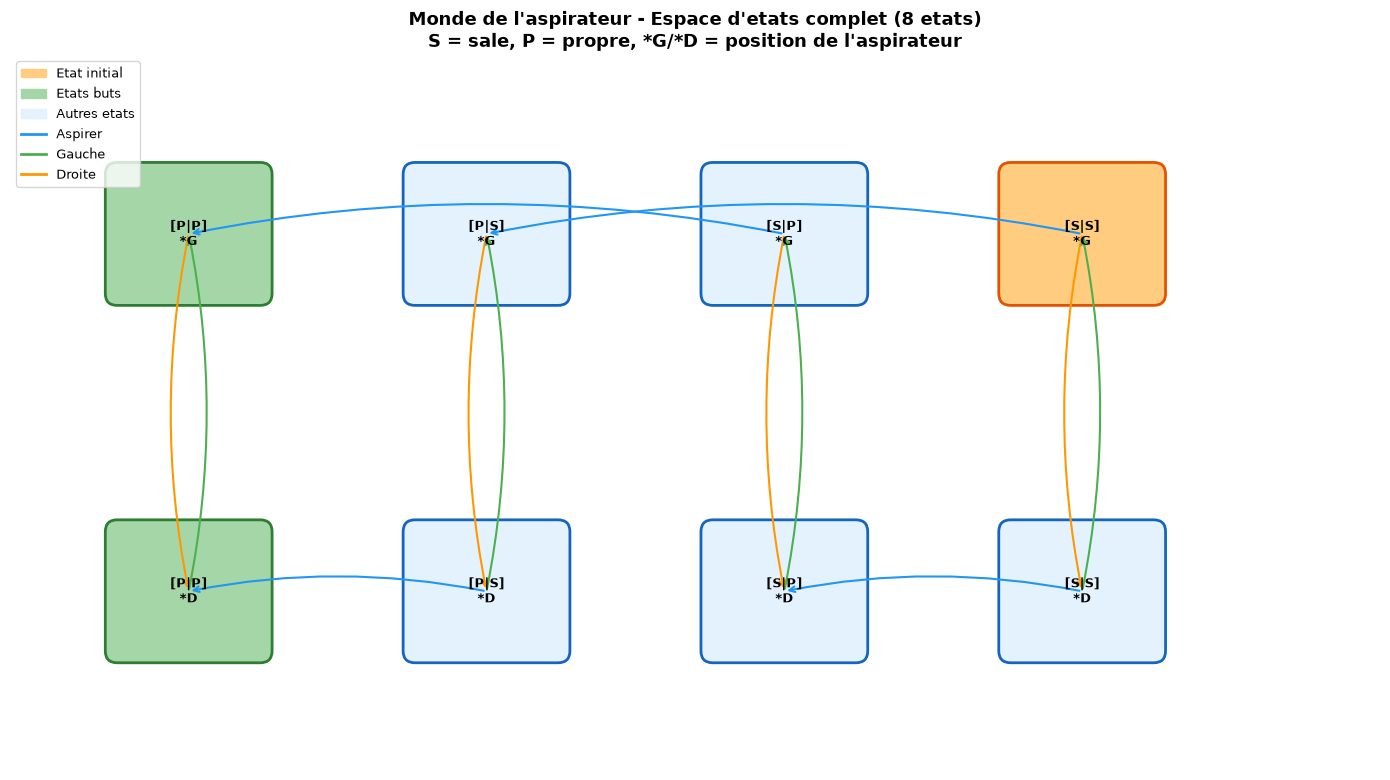

In [5]:
def visualize_vacuum_state_space(problem: VacuumWorld):
    """Visualise l'espace d'etats complet du monde de l'aspirateur."""
    all_states = problem.all_states()
    
    # Construire le graphe des transitions
    edges = []  # (source, target, action)
    for s in all_states:
        for a in problem.actions(s):
            s_prime = problem.transition(s, a)
            if s != s_prime:  # Ignorer les auto-boucles triviales
                edges.append((s, s_prime, a))
    
    # Representation textuelle des etats
    def state_label(s):
        pos, g, d = s
        g_str = "S" if g else "P"
        d_str = "S" if d else "P"
        return f"[{g_str}|{d_str}]\n*{pos}"
    
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Disposition manuelle en grille 2x4
    # Ligne du haut : aspirateur a Gauche, Ligne du bas : aspirateur a Droite
    positions = {}
    idx = 0
    for pos in ['G', 'D']:
        row = 0 if pos == 'G' else 1
        col = 0
        for g in [False, True]:
            for d in [False, True]:
                state = (pos, g, d)
                x = col * 2.5 + 1
                y = (1 - row) * 3 + 1
                positions[state] = (x, y)
                col += 1
    
    # Dessiner les aretes
    action_colors = {'Aspirer': '#2196F3', 'Gauche': '#4CAF50', 'Droite': '#FF9800'}
    drawn = set()
    for s, s_prime, a in edges:
        key = (s, s_prime)
        if key in drawn:
            continue
        drawn.add(key)
        x1, y1 = positions[s]
        x2, y2 = positions[s_prime]
        color = action_colors.get(a, 'gray')
        ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle='->', color=color, lw=1.5, 
                                   connectionstyle='arc3,rad=0.1'))
    
    # Dessiner les noeuds
    for state, (x, y) in positions.items():
        is_init = (state == problem.initial_state())
        is_goal = problem.is_goal(state)
        
        if is_goal:
            color = '#A5D6A7'  # Vert pour les buts
            ec = '#2E7D32'
        elif is_init:
            color = '#FFCC80'  # Orange pour l'initial
            ec = '#E65100'
        else:
            color = '#E3F2FD'  # Bleu clair
            ec = '#1565C0'
        
        rect = mpatches.FancyBboxPatch((x - 0.6, y - 0.5), 1.2, 1.0,
                                        boxstyle='round,pad=0.1',
                                        facecolor=color, edgecolor=ec, linewidth=2)
        ax.add_patch(rect)
        ax.text(x, y, state_label(state), ha='center', va='center',
                fontsize=9, fontweight='bold')
    
    # Legende
    legend_patches = [
        mpatches.Patch(color='#FFCC80', label='Etat initial'),
        mpatches.Patch(color='#A5D6A7', label='Etats buts'),
        mpatches.Patch(color='#E3F2FD', label='Autres etats'),
    ]
    legend_lines = [
        plt.Line2D([0], [0], color='#2196F3', lw=2, label='Aspirer'),
        plt.Line2D([0], [0], color='#4CAF50', lw=2, label='Gauche'),
        plt.Line2D([0], [0], color='#FF9800', lw=2, label='Droite'),
    ]
    ax.legend(handles=legend_patches + legend_lines, loc='upper left', fontsize=9)
    
    ax.set_xlim(-0.5, 11)
    ax.set_ylim(-0.5, 5.5)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title("Monde de l'aspirateur - Espace d'etats complet (8 etats)\n"
                 "S = sale, P = propre, *G/*D = position de l'aspirateur",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


visualize_vacuum_state_space(vacuum)

### Interpretation : Graphe d'etats de l'aspirateur

**Sortie obtenue** : Le graphe complet montre les 8 etats et les transitions possibles.

| Observation | Detail |
|-------------|--------|
| Etats buts | 2 etats (vert) : (G, propre, propre) et (D, propre, propre) |
| Etat initial | 1 etat (orange) : (G, sale, sale) |
| Transitions Aspirer | Vont vers des etats avec moins de salete (fleches bleues) |
| Transitions Gauche/Droite | Changent uniquement la position (fleches vertes/orange) |

**Points cles** :
1. L'action "Aspirer" dans une piece déjà propre ne change pas l'etat (auto-boucle, non affichée)
2. Depuis l'etat initial, il y a exactement **2 chemins optimaux** de longueur 3 vers un but
3. Le graphe est **connexe** : depuis tout etat, on peut atteindre un etat but

## 4. Exemple 2 : Le taquin (8-Puzzle)

### Description

Le **taquin** (8-Puzzle) est un casse-tete classique :
- Une grille 3x3 contenant 8 tuiles numerotees (1 a 8) et une case vide
- On deplace les tuiles en glissant dans la case vide
- **Objectif** : atteindre une configuration cible (1 a 8 en ordre)

### Modelisation

| Composant | Definition |
|-----------|------------|
| Etat | Tuple de 9 éléments (0 = case vide) |
| Actions | Haut, Bas, Gauche, Droite (deplace la case vide) |
| Transition | Echange la case vide avec la tuile adjacente |
| But | Configuration $(1, 2, 3, 4, 5, 6, 7, 8, 0)$ |
| Taille | $\frac{9!}{2} = 181\,440$ etats accessibles |

In [6]:
class EightPuzzle(SearchProblem):
    """
    Le taquin (8-Puzzle).
    
    Etat : tuple de 9 entiers, 0 represente la case vide.
    Exemple : (1, 2, 3, 4, 5, 6, 7, 8, 0) = etat but.
    """
    
    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
    
    # Mouvements possibles de la case vide selon sa position (index 0-8)
    MOVES = {
        0: {'Bas': 3, 'Droite': 1},
        1: {'Bas': 4, 'Gauche': 0, 'Droite': 2},
        2: {'Bas': 5, 'Gauche': 1},
        3: {'Haut': 0, 'Bas': 6, 'Droite': 4},
        4: {'Haut': 1, 'Bas': 7, 'Gauche': 3, 'Droite': 5},
        5: {'Haut': 2, 'Bas': 8, 'Gauche': 4},
        6: {'Haut': 3, 'Droite': 7},
        7: {'Haut': 4, 'Gauche': 6, 'Droite': 8},
        8: {'Haut': 5, 'Gauche': 7},
    }
    
    def __init__(self, start: tuple = None):
        if start is None:
            start = (7, 2, 4, 5, 0, 6, 8, 3, 1)  # Exemple de configuration
        self.start = start
    
    def initial_state(self):
        return self.start
    
    def actions(self, state) -> List[str]:
        blank_pos = state.index(0)
        return list(self.MOVES[blank_pos].keys())
    
    def transition(self, state, action):
        blank_pos = state.index(0)
        target_pos = self.MOVES[blank_pos][action]
        state_list = list(state)
        state_list[blank_pos], state_list[target_pos] = state_list[target_pos], state_list[blank_pos]
        return tuple(state_list)
    
    def is_goal(self, state) -> bool:
        return state == self.GOAL
    
    def state_space_size(self) -> int:
        # 9!/2 (la moitie des permutations sont atteignables)
        import math
        return math.factorial(9) // 2


# Creation
puzzle = EightPuzzle(start=(7, 2, 4, 5, 0, 6, 8, 3, 1))
s0 = puzzle.initial_state()

print(f"Taille de l'espace d'etats : {puzzle.state_space_size():,} etats")
print(f"Etat initial : {s0}")
print(f"Etat but :     {EightPuzzle.GOAL}")
print(f"Actions depuis l'etat initial : {puzzle.actions(s0)}")

Taille de l'espace d'etats : 181,440 etats
Etat initial : (7, 2, 4, 5, 0, 6, 8, 3, 1)
Etat but :     (1, 2, 3, 4, 5, 6, 7, 8, 0)
Actions depuis l'etat initial : ['Haut', 'Bas', 'Gauche', 'Droite']


### Affichage visuel du taquin

Pour mieux comprendre le problème, affichons les etats du taquin sous forme de grilles graphiques.

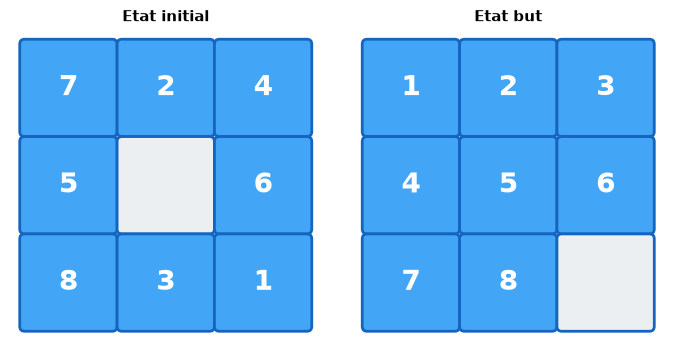

In [7]:
def draw_puzzle_state(state: tuple, ax=None, title=""):
    """Affiche un etat du taquin sous forme de grille 3x3."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(3, 3))
    
    for i in range(9):
        row, col = divmod(i, 3)
        value = state[i]
        
        if value == 0:
            color = '#ECEFF1'  # Gris clair pour case vide
            text_color = '#ECEFF1'
        else:
            color = '#42A5F5'  # Bleu pour les tuiles
            text_color = 'white'
        
        rect = mpatches.FancyBboxPatch((col - 0.45, 2 - row - 0.45), 0.9, 0.9,
                                        boxstyle='round,pad=0.05',
                                        facecolor=color, edgecolor='#1565C0',
                                        linewidth=2)
        ax.add_patch(rect)
        
        if value != 0:
            ax.text(col, 2 - row, str(value), ha='center', va='center',
                    fontsize=20, fontweight='bold', color=text_color)
    
    ax.set_xlim(-0.6, 2.6)
    ax.set_ylim(-0.6, 2.6)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=11, fontweight='bold')


def draw_puzzle_sequence(states: List[tuple], actions: List[str] = None, title=""):
    """Affiche une sequence d'etats du taquin."""
    n = len(states)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5))
    if n == 1:
        axes = [axes]
    
    for i, (state, ax) in enumerate(zip(states, axes)):
        step_title = f"Etape {i}"
        if actions and i > 0:
            step_title += f"\n({actions[i-1]})"
        elif i == 0:
            step_title = "Initial"
        draw_puzzle_state(state, ax, step_title)
    
    fig.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


# Afficher l'etat initial et le but
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
draw_puzzle_state(puzzle.initial_state(), axes[0], "Etat initial")
draw_puzzle_state(EightPuzzle.GOAL, axes[1], "Etat but")
plt.tight_layout()
plt.show()

### Exploration de quelques mouvements

Appliquons quelques actions depuis l'etat initial pour observer les transitions.

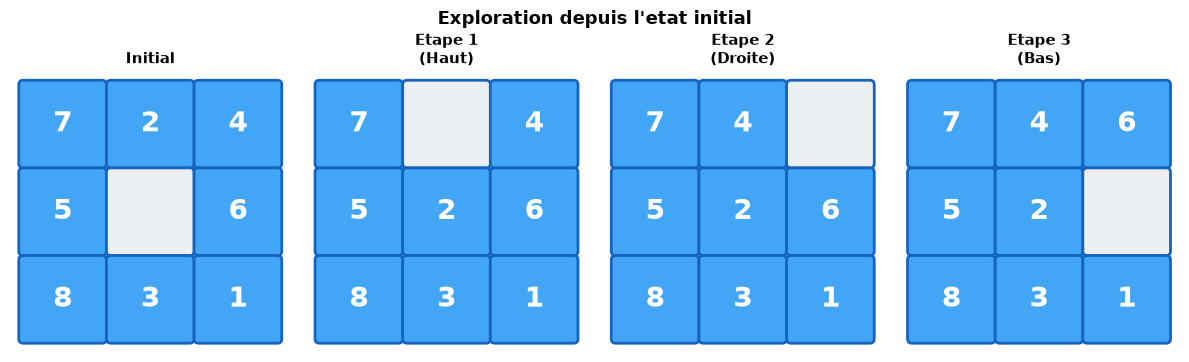

Facteur de branchement selon la position de la case vide :
  Coin (positions 0,2,6,8) : 2 actions
  Bord (positions 1,3,5,7) : 3 actions
  Centre (position 4)      : 4 actions
  Facteur de branchement moyen : 2.67


In [8]:
# Simuler quelques mouvements
s0 = puzzle.initial_state()
actions_demo = ['Haut', 'Droite', 'Bas']

states_seq = [s0]
current = s0
for a in actions_demo:
    current = puzzle.transition(current, a)
    states_seq.append(current)

# Afficher la sequence
draw_puzzle_sequence(states_seq, actions_demo, "Exploration depuis l'etat initial")

# Montrer le facteur de branchement
print("Facteur de branchement selon la position de la case vide :")
print(f"  Coin (positions 0,2,6,8) : 2 actions")
print(f"  Bord (positions 1,3,5,7) : 3 actions")
print(f"  Centre (position 4)      : 4 actions")
print(f"  Facteur de branchement moyen : {(4*2 + 4*3 + 1*4)/9:.2f}")

### Interpretation : Transitions du taquin

**Sortie obtenue** : Trois mouvements successifs de la case vide, avec le facteur de branchement.

| Propriete | Valeur | Consequence |
|-----------|--------|-------------|
| Facteur de branchement moyen | ~2.67 | L'arbre de recherche croit rapidement |
| Espace d'etats | 181 440 | Grand mais fini, explorable par BFS/DFS |
| Solution optimale typique | 20-30 coups | Difficulte variable selon la configuration initiale |

**Points cles** :
1. Les actions "Haut", "Bas", "Gauche", "Droite" deplacent la **case vide**, pas une tuile spécifique
2. Le nombre d'actions varie de 2 (coin) a 4 (centre)
3. La profondeur maximale de la solution optimale pour le 8-puzzle est de 31 coups

> **Note** : Le 15-puzzle (grille 4x4) a environ $10^{13}$ etats et le 24-puzzle (grille 5x5) environ $10^{25}$ etats.

## 5. Exemple 3 : Recherche d'itineraire

### Description

Le problème de **recherche d'itineraire** consiste a trouver le chemin le plus court entre deux villes dans un reseau routier. C'est l'application la plus intuitive de la recherche dans un espace d'etats.

### Modelisation

| Composant | Definition |
|-----------|------------|
| Etat | Ville actuelle |
| Actions | Se deplacer vers une ville voisine |
| Transition | Changer de ville |
| Cout | Distance entre les deux villes |
| But | Arriver a la ville de destination |

In [9]:
class RouteFinding(SearchProblem):
    """
    Probleme de recherche d'itineraire dans un graphe de villes.
    
    Le graphe est represente par un dictionnaire d'adjacence
    avec les distances entre villes voisines.
    """
    
    def __init__(self, graph: dict, start: str, goal: str):
        """
        Args:
            graph: dict {ville: [(voisin, distance), ...]}
            start: ville de depart
            goal: ville d'arrivee
        """
        self.graph = graph
        self.start_city = start
        self.goal_city = goal
    
    def initial_state(self):
        return self.start_city
    
    def actions(self, state) -> List[str]:
        return [neighbor for neighbor, _ in self.graph.get(state, [])]
    
    def transition(self, state, action):
        return action  # L'action est la ville de destination
    
    def is_goal(self, state) -> bool:
        return state == self.goal_city
    
    def cost(self, state, action, next_state) -> float:
        for neighbor, distance in self.graph.get(state, []):
            if neighbor == next_state:
                return distance
        return float('inf')
    
    def state_space_size(self) -> int:
        return len(self.graph)


# Reseau de villes francaises (distances approximatives en km)
france_graph = {
    'Paris':      [('Lyon', 465), ('Lille', 225), ('Strasbourg', 490), ('Nantes', 385), ('Bordeaux', 585)],
    'Lyon':       [('Paris', 465), ('Marseille', 315), ('Grenoble', 105), ('Strasbourg', 490)],
    'Marseille':  [('Lyon', 315), ('Montpellier', 170), ('Nice', 200)],
    'Lille':      [('Paris', 225), ('Strasbourg', 525)],
    'Strasbourg': [('Paris', 490), ('Lyon', 490), ('Lille', 525)],
    'Bordeaux':   [('Paris', 585), ('Toulouse', 245), ('Nantes', 345)],
    'Toulouse':   [('Bordeaux', 245), ('Montpellier', 245)],
    'Montpellier':[('Toulouse', 245), ('Marseille', 170)],
    'Nantes':     [('Paris', 385), ('Bordeaux', 345)],
    'Nice':       [('Marseille', 200)],
    'Grenoble':   [('Lyon', 105)],
}

# Probleme : aller de Bordeaux a Strasbourg
route = RouteFinding(france_graph, 'Bordeaux', 'Strasbourg')

print(f"Depart : {route.start_city}")
print(f"Arrivee : {route.goal_city}")
print(f"Nombre de villes : {route.state_space_size()}")
print(f"Actions depuis Bordeaux : {route.actions('Bordeaux')}")
print(f"Cout Bordeaux -> Paris : {route.cost('Bordeaux', 'Paris', 'Paris')} km")

Depart : Bordeaux
Arrivee : Strasbourg
Nombre de villes : 11
Actions depuis Bordeaux : ['Paris', 'Toulouse', 'Nantes']
Cout Bordeaux -> Paris : 585 km


### Visualisation de la carte

Dessinons le reseau routier avec matplotlib, en positionnant chaque ville a ses coordonnees geographiques approximatives : le graphe ressemble ainsi a une carte.

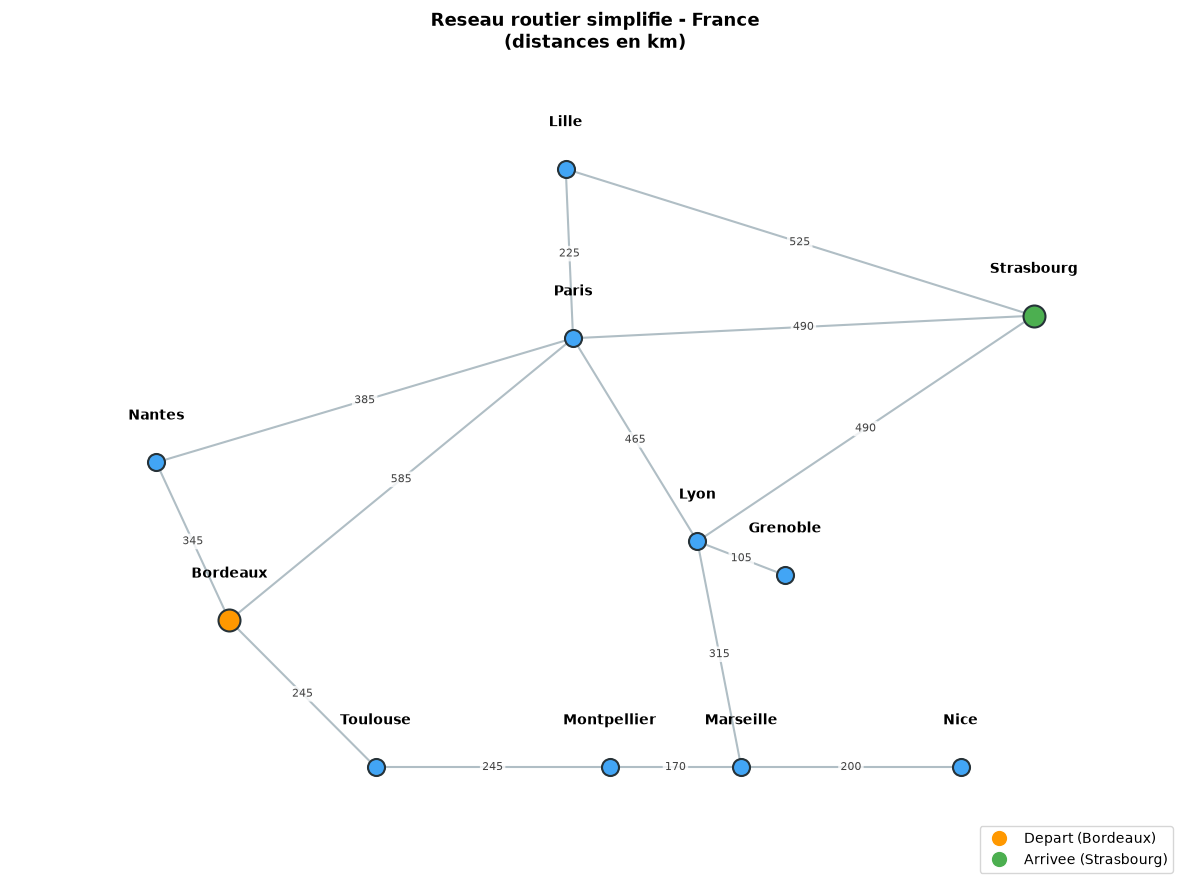

In [10]:
def visualize_route_graph(graph: dict, start: str = None, goal: str = None,
                          path: List[str] = None):
    """Visualise le graphe routier avec positions geographiques approximatives."""
    
    # Positions approximatives (longitude, latitude normalisees)
    city_positions = {
        'Paris':       (2.35, 6.3),
        'Lyon':        (3.2, 4.5),
        'Marseille':   (3.5, 2.5),
        'Lille':       (2.3, 7.8),
        'Strasbourg':  (5.5, 6.5),
        'Bordeaux':    (0.0, 3.8),
        'Toulouse':    (1.0, 2.5),
        'Montpellier': (2.6, 2.5),
        'Nantes':      (-0.5, 5.2),
        'Nice':        (5.0, 2.5),
        'Grenoble':    (3.8, 4.2),
    }
    
    fig, ax = plt.subplots(figsize=(12, 9))
    
    # Dessiner les aretes
    drawn_edges = set()
    for city, neighbors in graph.items():
        for neighbor, dist in neighbors:
            edge_key = tuple(sorted([city, neighbor]))
            if edge_key not in drawn_edges:
                drawn_edges.add(edge_key)
                x1, y1 = city_positions[city]
                x2, y2 = city_positions[neighbor]
                
                # Couleur speciale si dans le chemin
                is_path_edge = False
                if path:
                    for i in range(len(path) - 1):
                        if edge_key == tuple(sorted([path[i], path[i+1]])):
                            is_path_edge = True
                            break
                
                color = '#E53935' if is_path_edge else '#B0BEC5'
                lw = 3 if is_path_edge else 1.5
                
                ax.plot([x1, x2], [y1, y2], '-', color=color, linewidth=lw, zorder=1)
                
                # Distance au milieu de l'arete
                mx, my = (x1 + x2) / 2, (y1 + y2) / 2
                ax.text(mx, my, f"{dist}", ha='center', va='center',
                        fontsize=8, color='#424242',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', 
                                  edgecolor='none', alpha=0.8))
    
    # Dessiner les villes
    for city, (x, y) in city_positions.items():
        if city == start:
            color = '#FF9800'
            size = 250
        elif city == goal:
            color = '#4CAF50'
            size = 250
        elif path and city in path:
            color = '#E53935'
            size = 200
        else:
            color = '#42A5F5'
            size = 150
        
        ax.scatter(x, y, s=size, c=color, edgecolors='#263238', linewidth=1.5, zorder=3)
        ax.text(x, y + 0.35, city, ha='center', va='bottom',
                fontsize=10, fontweight='bold')
    
    # Legende
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#FF9800',
                   markersize=12, label=f'Depart ({start})' if start else 'Depart'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#4CAF50',
                   markersize=12, label=f'Arrivee ({goal})' if goal else 'Arrivee'),
    ]
    if path:
        legend_elements.append(
            plt.Line2D([0], [0], color='#E53935', linewidth=3, label='Chemin')
        )
    ax.legend(handles=legend_elements, loc='lower right', fontsize=10)
    
    ax.set_xlim(-1.5, 6.5)
    ax.set_ylim(1.5, 8.8)
    ax.set_title("Reseau routier simplifie - France\n(distances en km)",
                 fontsize=13, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()


# Afficher la carte
visualize_route_graph(france_graph, start='Bordeaux', goal='Strasbourg')

### Interpretation : Reseau routier

**Sortie obtenue** : La carte montre 11 villes et les liaisons routieres avec distances en km.

| Observation | Detail |
|-------------|--------|
| Depart (orange) | Bordeaux, sud-ouest |
| Arrivee (vert) | Strasbourg, est |
| Chemins possibles | Via Paris (Bordeaux-Paris-Strasbourg = 1075 km) |
| | Via Toulouse-Lyon (Bordeaux-Toulouse-Montpellier-Marseille-Lyon-Strasbourg) |

**Points cles** :
1. Le cout (distance) est **variable** : contrairement a l'aspirateur et au taquin, chaque action a un cout différent
2. Le graphe n'est pas complet : toutes les villes ne sont pas directement reliees
3. La solution la plus courte en nombre d'étapes n'est pas forcement la plus courte en distance

### Comparaison de deux itineraires

Comparons un itineraire direct (peu d'étapes) et un itineraire avec plus d'étapes pour illustrer la différence entre nombre d'étapes et cout total.

In [11]:
def evaluate_path(problem: RouteFinding, path: List[str]):
    """Evalue un itineraire : cout total et nombre d'etapes."""
    total_cost = 0
    segments = []
    for i in range(len(path) - 1):
        c = problem.cost(path[i], path[i+1], path[i+1])
        total_cost += c
        segments.append((path[i], path[i+1], c))
    return total_cost, segments


# Itineraire 1 : via Paris (direct)
path1 = ['Bordeaux', 'Paris', 'Strasbourg']
cost1, segments1 = evaluate_path(route, path1)

# Itineraire 2 : via le sud
path2 = ['Bordeaux', 'Toulouse', 'Montpellier', 'Marseille', 'Lyon', 'Strasbourg']
cost2, segments2 = evaluate_path(route, path2)

print("Comparaison de deux itineraires Bordeaux -> Strasbourg")
print("=" * 60)

print(f"\nItineraire 1 : via Paris")
print(f"  Nombre d'etapes : {len(path1) - 1}")
for s, d, c in segments1:
    print(f"  {s} -> {d} : {c} km")
print(f"  Distance totale : {cost1} km")

print(f"\nItineraire 2 : via le sud")
print(f"  Nombre d'etapes : {len(path2) - 1}")
for s, d, c in segments2:
    print(f"  {s} -> {d} : {c} km")
print(f"  Distance totale : {cost2} km")

print(f"\nDifference : {abs(cost1 - cost2)} km")
print(f"Le chemin le plus court est l'itineraire {'1 (via Paris)' if cost1 <= cost2 else '2 (via le sud)'}")

Comparaison de deux itineraires Bordeaux -> Strasbourg

Itineraire 1 : via Paris
  Nombre d'etapes : 2
  Bordeaux -> Paris : 585 km
  Paris -> Strasbourg : 490 km
  Distance totale : 1075 km

Itineraire 2 : via le sud
  Nombre d'etapes : 5
  Bordeaux -> Toulouse : 245 km
  Toulouse -> Montpellier : 245 km
  Montpellier -> Marseille : 170 km
  Marseille -> Lyon : 315 km
  Lyon -> Strasbourg : 490 km
  Distance totale : 1465 km

Difference : 390 km
Le chemin le plus court est l'itineraire 1 (via Paris)


### Interpretation : Nombre d'étapes vs cout

**Sortie obtenue** : Deux itineraires de longueurs différentes en nombre d'étapes et en distance.

| Itineraire | Étapes | Distance totale | Commentaire |
|------------|--------|-----------------|-------------|
| Via Paris | 2 | 1075 km | Peu d'étapes, mais long |
| Via le sud | 5 | 1465 km | Plus d'étapes et plus long |

**Lecon fondamentale** : La distinction entre **recherche en largeur** (minimise le nombre d'étapes) et **recherche au cout uniforme** (minimise le cout total) est cruciale. Dans cet exemple :
- BFS choisirait l'itineraire 1 (2 étapes)
- La recherche au cout uniforme pourrait trouver un chemin moins cher en explorant d'autres options

> L'algorithme **A*** combine les deux en utilisant une heuristique pour guider la recherche. Nous l'etudierons dans le notebook suivant.

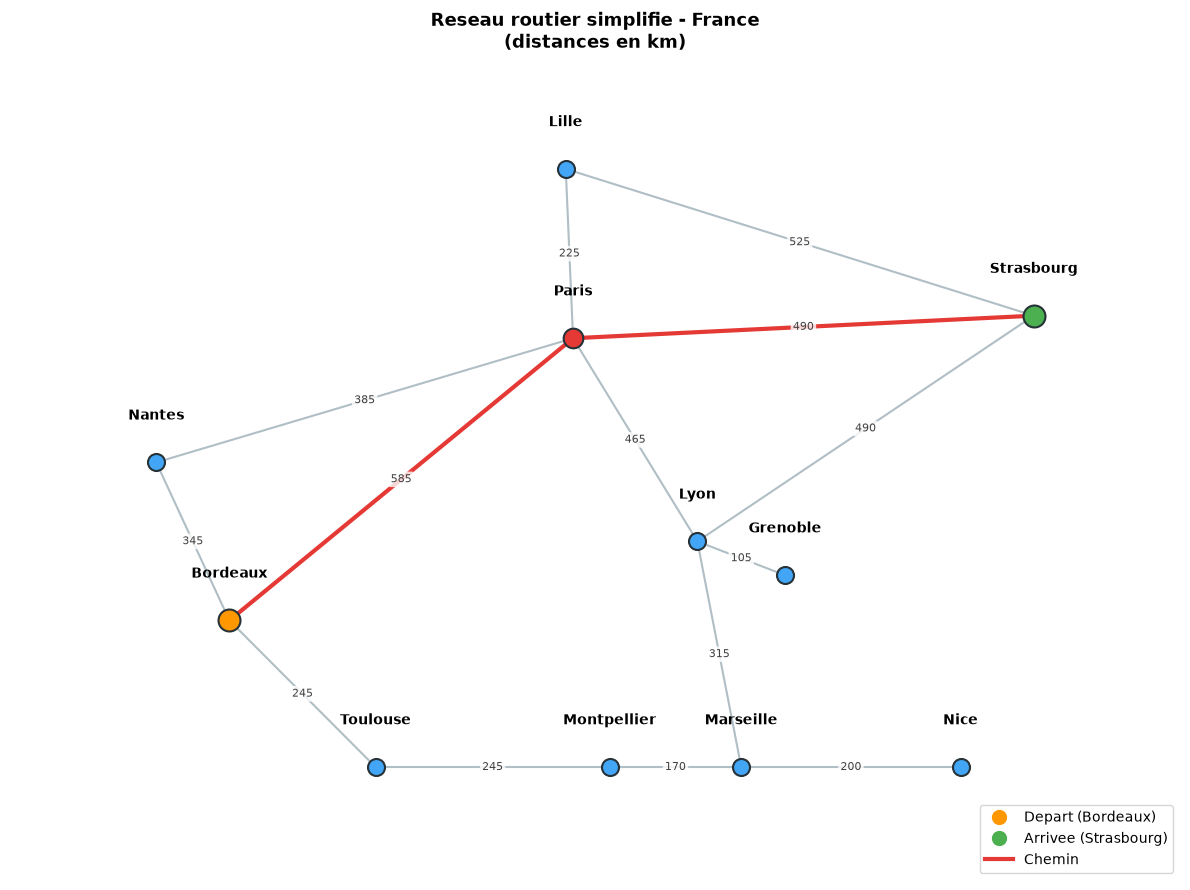

In [12]:
# Afficher le chemin via Paris sur la carte
visualize_route_graph(france_graph, start='Bordeaux', goal='Strasbourg',
                      path=['Bordeaux', 'Paris', 'Strasbourg'])

### Verification de l'optimalite avec networkx

Comparer deux itineraires choisis a la main etablit leur ordre relatif, rien de plus : seul un parcours systematique du graphe prouve l'optimalite. Utilisons **networkx**, qui fournit l'algorithme de Dijkstra et des mesures de graphe inaccessibles a la bibliotheque standard.

> **Note de parite avec le jumeau C#** : `Search-01-StateSpace-CSharp.ipynb` decrit un graphe **different** -- 13 villes (Brest, Rennes en plus), 41 arcs diriges, facteur de branchement 3.15, un arc sans reciproque, et des poids divergents (Bordeaux-Toulouse : 250 km contre 245 ici). Sur ce graphe, l'optimum `Bordeaux -> Strasbourg` vaut **1045 km via Lyon** : le moteur y **infirme** l'itineraire declare vainqueur a la main. Sur le graphe du present notebook (11 villes, 28 arcs symetriques, facteur de branchement 2.55), l'optimum est **1075 km via Paris** : le moteur le **confirme**. Les deux lecons sont valides mais distinctes ; l'ecart est consigne dans le registre de parite (`scripts/notebook_tools/twin_pairs.d/search-1-statespace.yaml`).

In [13]:
# Confier le graphe deja defini a networkx (sans dupliquer les donnees)
G = nx.DiGraph()
for city, neighbors in france_graph.items():
    for neighbor, dist in neighbors:
        G.add_edge(city, neighbor, weight=dist)

# Dijkstra = UCS sur un graphe pondere a couts positifs
path = nx.dijkstra_path(G, 'Bordeaux', 'Strasbourg', weight='weight')
length = nx.dijkstra_path_length(G, 'Bordeaux', 'Strasbourg', weight='weight')
print(f"Chemin optimal (networkx) : {' -> '.join(path)}")
print(f"Distance totale           : {length} km")
print(f"Facteur de branchement    : {G.number_of_edges() / G.number_of_nodes():.2f} ({G.number_of_edges()} arcs / {G.number_of_nodes()} villes)")

# Centralite d'intermediarite : role structurel, mesure que la stdlib ne sait pas calculer
centrality = nx.betweenness_centrality(G, weight='weight')
print()
print("Centralite d'intermediarite (top 3) :")
for city, c in sorted(centrality.items(), key=lambda kv: -kv[1])[:3]:
    print(f"  {city:<12} {c:.3f}")

Chemin optimal (networkx) : Bordeaux -> Paris -> Strasbourg
Distance totale           : 1075 km
Facteur de branchement    : 2.55 (28 arcs / 11 villes)

Centralite d'intermediarite (top 3) :
  Lyon         0.422
  Marseille    0.422
  Paris        0.267


### Lecture du resultat

Dijkstra **confirme** ici l'itineraire via Paris (1075 km) : le choix fait a la main etait deja optimal sur ce graphe. C'est le cas le moins spectaculaire d'une verification -- mais c'est precisement le sens de la demarche : elle separe ce qui est *prouve* par un parcours systematique de ce qui est seulement *suppose*.

La **centralite d'intermediarite** ajoute une information que la recherche seule ne fournit pas : ce sont **Lyon et Marseille** (0.422) qui portent le trafic sud-nord -- quasi tous les plus courts chemins entre le sud et le nord passent par l'une des deux --, Paris n'arrivant qu'en troisieme position (0.267). C'est une mesure de role *structurel* dans le graphe entier, pas un cout de trajet : un parcours depuis un unique depart ne la voit jamais.

## 6. Proprietes des problemes de recherche

### Classification des problemes

Les problemes de recherche se distinguent par plusieurs proprietes qui influencent le choix de l'algorithme de resolution.

In [14]:
# Tableau comparatif des trois problemes
properties = [
    ["Propriete", "Aspirateur", "8-Puzzle", "Itineraire"],
    ["Observable", "Oui", "Oui", "Oui"],
    ["Deterministe", "Oui", "Oui", "Oui"],
    ["Discret", "Oui", "Oui", "Oui"],
    ["Statique", "Oui", "Oui", "Oui"],
    ["Agent unique", "Oui", "Oui", "Oui"],
    ["-" * 20, "-" * 15, "-" * 15, "-" * 15],
    ["Taille |S|", "8", "181 440", "Variable (~11)"],
    ["Facteur branch.", "2", "~2.67", "Variable (~2.55)"],
    ["Cout uniforme", "Oui (1 par action)", "Oui (1 par action)", "Non (distances)"],
    ["Prof. solution", "2-3", "~22 (moy.)", "Variable"],
    ["Reversible", "Partiellement", "Oui", "Oui"],
]

# Affichage formate
print("Comparaison des trois problemes de recherche")
print("=" * 70)

for row in properties:
    print(f"{row[0]:<20} {row[1]:<15} {row[2]:<15} {row[3]:<15}")

Comparaison des trois problemes de recherche
Propriete            Aspirateur      8-Puzzle        Itineraire     
Observable           Oui             Oui             Oui            
Deterministe         Oui             Oui             Oui            
Discret              Oui             Oui             Oui            
Statique             Oui             Oui             Oui            
Agent unique         Oui             Oui             Oui            
-------------------- --------------- --------------- ---------------
Taille |S|           8               181 440         Variable (~11) 
Facteur branch.      2               ~2.67           Variable (~2.55)
Cout uniforme        Oui (1 par action) Oui (1 par action) Non (distances)
Prof. solution       2-3             ~22 (moy.)      Variable       
Reversible           Partiellement   Oui             Oui            


### Interpretation : Comparaison des proprietes

Les trois problemes partagent des proprietes importantes qui les rendent accessibles aux algorithmes de recherche classiques :

| Propriete | Signification | Consequence algorithmique |
|-----------|---------------|---------------------------|
| **Observable** | L'agent connait l'etat complet | Pas besoin de perception partielle |
| **Déterministe** | Chaque action a un résultat unique | Pas de probabilites a gerer |
| **Discret** | Nombre fini d'etats et d'actions | Enumeration possible |
| **Statique** | Le monde ne change pas entre les actions | L'agent peut planifier hors-ligne |
| **Agent unique** | Pas d'adversaire | Pas besoin de théorie des jeux |

**Différences significatives** :

| Différence | Impact |
|------------|--------|
| Taille de l'espace | Le 8-puzzle est 22 000 fois plus grand que l'aspirateur |
| Cout uniforme ou non | L'itineraire necessite UCS ou A* (BFS ne suffit pas pour l'optimalite) |
| Reversibilite | Le taquin est totalement reversible, l'aspirateur ne l'est que partiellement |

> **Problemes plus complexes** : Quand ces proprietes ne sont pas satisfaites (non-determinisme, observabilite partielle, multi-agents), il faut des algorithmes specialises (POMDP, jeux, planification probabiliste).

## 7. Exercices

### Exemple guidé — Missionnaires et cannibales

*Exercice 1 résolu dans la PR #22688 et repris ici comme exemple guidé.*

Trois missionnaires et trois cannibales doivent traverser une rivière dans un bateau qui ne peut transporter que 2 personnes. Si les cannibales sont plus nombreux que les missionnaires sur une rive, les missionnaires sont dévorés.

**Modélisation** :
- État : `(m_gauche, c_gauche, bateau)` où `m_gauche` = missionnaires sur la rive gauche, `c_gauche` = cannibales sur la rive gauche, `bateau` = 'G' ou 'D'
- Actions : nombre de missionnaires et de cannibales dans le bateau, `(m, c)` avec $1 \le m + c \le 2$
- Contrainte : jamais plus de cannibales que de missionnaires sur une rive (sauf si cette rive n'a aucun missionnaire)

**Ce que montre la solution** :
- `_is_valid` contrôle les **deux** rives : la rive droite se déduit de la gauche (`3 - m_gauche`, `3 - c_gauche`), il n'est donc pas nécessaire de la stocker dans l'état ;
- `actions` ne propose que les chargements possibles depuis la rive où se trouve le bateau, puis écarte ceux qui mèneraient à un état non sûr : depuis l'état initial, `(2, 0)` est refusé parce qu'il laisserait 1 missionnaire face à 3 cannibales sur la rive gauche ;
- `state_space_size` énumère les 32 triplets `(m, c, bateau)` et compte ceux qui sont sûrs.

In [15]:
class MissionariesCannibals(SearchProblem):
    """
    Exemple guide (solution de la PR #22688) : Missionnaires et Cannibales.

    Etat : (missionnaires_gauche, cannibales_gauche, position_bateau)
    Etat initial : (3, 3, 'G')  - tout le monde a gauche
    But : (0, 0, 'D')           - tout le monde a droite
    """

    def initial_state(self):
        return (3, 3, 'G')

    def _is_valid(self, state) -> bool:
        """Verifie que l'etat est valide (pas de missionnaire devore)."""
        m_g, c_g, b = state
        m_d, c_d = 3 - m_g, 3 - c_g

        if not (0 <= m_g <= 3 and 0 <= c_g <= 3):
            return False
        if m_g > 0 and c_g > m_g:
            return False
        if m_d > 0 and c_d > m_d:
            return False
        return True

    def actions(self, state) -> List[Tuple[int, int]]:
        """Retourne les actions possibles : (missionnaires, cannibales) dans le bateau."""
        m_g, c_g, b = state
        if b == 'G':
            m_dispo, c_dispo = m_g, c_g
        else:
            m_dispo, c_dispo = 3 - m_g, 3 - c_g

        result = []
        for m in range(3):
            for c in range(3):
                if 1 <= m + c <= 2 and m <= m_dispo and c <= c_dispo:
                    if self._is_valid(self.transition(state, (m, c))):
                        result.append((m, c))
        return result

    def transition(self, state, action):
        m_g, c_g, b = state
        m, c = action
        if b == 'G':
            return (m_g - m, c_g - c, 'D')
        else:
            return (m_g + m, c_g + c, 'G')

    def is_goal(self, state) -> bool:
        return state == (0, 0, 'D')

    def state_space_size(self) -> int:
        """Compte le nombre d'etats valides."""
        return sum(
            1
            for m in range(4)
            for c in range(4)
            for b in ('G', 'D')
            if self._is_valid((m, c, b))
        )


mc = MissionariesCannibals()
s0 = mc.initial_state()
print(f"Etat initial : {s0} (3M, 3C a gauche, bateau a gauche)")
print(f"Nombre d'etats valides : {mc.state_space_size()} (sur 4 x 4 x 2 = 32 triplets)")
print(f"Actions possibles : {mc.actions(s0)}")
print("  (m, c) = nombre de missionnaires et cannibales dans le bateau")

Etat initial : (3, 3, 'G') (3M, 3C a gauche, bateau a gauche)
Nombre d'etats valides : 20 (sur 4 x 4 x 2 = 32 triplets)
Actions possibles : [(0, 1), (0, 2), (1, 1)]
  (m, c) = nombre de missionnaires et cannibales dans le bateau


### Résolution par recherche en largeur

La cellule suivante définit `bfs_solve`, une recherche en largeur (BFS) que le labyrinthe et les exercices réutilisent plus bas :
- la file (`deque`) contient des paires `(état, liste_actions)` ;
- un ensemble `visited` marque les états déjà rencontrés : sans lui, les allers-retours du bateau feraient tourner la recherche indéfiniment ;
- la recherche s'arrête au premier état qui vérifie `problem.is_goal(state)`.

Comme chaque traversée coûte 1, le premier chemin trouvé par BFS est aussi le plus court en nombre de traversées.

In [16]:
def bfs_solve(problem: SearchProblem):
    """Recherche en largeur simple (BFS) pour trouver une solution."""
    start = problem.initial_state()
    queue = deque([(start, [])])  # (etat, liste_actions)
    visited = {start}

    while queue:
        state, path = queue.popleft()

        if problem.is_goal(state):
            return path, state

        for action in problem.actions(state):
            next_state = problem.transition(state, action)
            if next_state not in visited:
                visited.add(next_state)
                queue.append((next_state, path + [action]))

    return None, None


# Resoudre Missionnaires et Cannibales
solution, final = bfs_solve(mc)

if solution:
    print(f"Solution trouvee en {len(solution)} traversees :\n")
    state = mc.initial_state()
    print(f"{'Etape':<8} {'Action (M,C)':<15} {'Rive gauche':<20} {'Rive droite':<20} {'Bateau'}")
    print("-" * 75)
    m_g, c_g, b = state
    print(f"{'init':<8} {'-':<15} {f'{m_g}M {c_g}C':<20} {f'{3-m_g}M {3-c_g}C':<20} {b}")

    for i, action in enumerate(solution, 1):
        state = mc.transition(state, action)
        m_g, c_g, b = state
        direction = "->" if b == 'D' else "<-"
        print(f"{i:<8} {str(action) + ' ' + direction:<15} {f'{m_g}M {c_g}C':<20} {f'{3-m_g}M {3-c_g}C':<20} {b}")
else:
    print("Pas de solution trouvee.")

Solution trouvee en 11 traversees :

Etape    Action (M,C)    Rive gauche          Rive droite          Bateau
---------------------------------------------------------------------------
init     -               3M 3C                0M 0C                G
1        (0, 2) ->       3M 1C                0M 2C                D
2        (0, 1) <-       3M 2C                0M 1C                G
3        (0, 2) ->       3M 0C                0M 3C                D
4        (0, 1) <-       3M 1C                0M 2C                G
5        (2, 0) ->       1M 1C                2M 2C                D
6        (1, 1) <-       2M 2C                1M 1C                G
7        (2, 0) ->       0M 2C                3M 1C                D
8        (0, 1) <-       0M 3C                3M 0C                G
9        (0, 2) ->       0M 1C                3M 2C                D
10       (0, 1) <-       0M 2C                3M 1C                G
11       (0, 2) ->       0M 0C                3M 3C   

### Interprétation : Missionnaires et cannibales

**Sortie obtenue** : 20 états valides sur les 32 triplets possibles, et seulement trois chargements autorisés au départ, `(0, 1)`, `(0, 2)` et `(1, 1)`. BFS trouve une traversée en **11 étapes**. C'est la solution optimale connue : BFS rend le chemin le plus court en nombre de traversées.

**Lecture du tableau** :
1. Les quatre premières traversées ne font passer que des cannibales : tant que les trois missionnaires restent ensemble sur la rive gauche, aucune rive n'est en danger.
2. À l'étape 6, un missionnaire et un cannibale **reviennent** sur la rive de départ : la solution doit parfois s'éloigner du but pour l'atteindre.
3. Après l'étape 7, les trois missionnaires sont à droite, et le bateau ne fait plus que des allers-retours de cannibales.

**Points clés** :
1. L'espace d'états est petit, mais les contraintes le rendent non trivial : la contrainte de sécurité élimine 12 des 32 triplets avant toute recherche.
2. Le problème est **réversible** : le bateau doit revenir pour continuer les traversées.
3. Le marquage des états visités est indispensable : chaque traversée peut être annulée par la traversée inverse.

> Ce problème illustre que la **taille de l'espace d'états** ne détermine pas à elle seule la difficulté. Les contraintes jouent un rôle crucial.

### Exemple guidé — Taille de l'espace d'états des taquins

*Exercice 2, résolu dans la PR #22645 puis consolidé avec la version de la PR #22991 (classe MIS G03) ; repris ici comme exemple guidé.*

**Question d'origine** : calculer la taille de l'espace d'états du **15-puzzle** (grille 4x4) et la comparer à celle des autres taquins.

**Ce que montre la solution** :
- la fonction `taille_espace(k)` renvoie $n = k^2$, $n!$ et $n!/2$ pour un taquin $k \times k$ ;
- la factorielle est calculée par une boucle multiplicative, puis confrontée à `math.factorial` jusqu'à $n = 25$ : l'occasion de constater que les entiers Python n'ont pas de limite de taille, là où un entier 64 bits déborderait dès $21!$ ;
- deux assertions confrontent le résultat aux valeurs connues : 181 440 états accessibles pour le 8-puzzle, 10 461 394 944 000 pour le 15-puzzle ;
- le plus petit taquin non trivial (3-puzzle, grille 2x2) sert de cas limite ;
- un ordre de grandeur du temps d'énumération, à un milliard d'états par seconde, traduit l'explosion factorielle en durée — et rappelle que mémoriser tous les états visités demanderait des dizaines de téraoctets dès le 15-puzzle.

La division par 2 repose sur l'**invariant de parité** : seule la moitié des permutations est atteignable par glissements. L'exercice 4 ci-dessous vous demande de le vérifier au lieu de l'admettre.

In [17]:
import math

# Exemple guide : taille de l'espace d'etats des taquins k x k
# (exercice 2 resolu dans la PR #22645, consolide avec la version de la PR #22991)
puzzles = [
    ("3-puzzle",  2,  4),   # cas limite : plus petit taquin non trivial
    ("8-puzzle",  3,  9),
    ("15-puzzle", 4, 16),
    ("24-puzzle", 5, 25),
]


# La factorielle se calcule par une boucle multiplicative. En Python les entiers
# n'ont pas de limite de taille : 25! se calcule exactement, la ou un entier
# 64 bits deborderait des 21!.
def factorielle(n):
    resultat = 1
    for i in range(2, n + 1):
        resultat *= i
    return resultat


# Controle de la boucle contre la factorielle de la bibliotheque standard.
for n in range(26):
    assert factorielle(n) == math.factorial(n), f"factorielle({n}) incorrecte"


def taille_espace(k):
    """Retourne (n, n!, n!/2) pour un taquin k x k, avec n = k*k cases."""
    n = k * k
    total = factorielle(n)         # toutes les permutations des n cases
    accessibles = total // 2       # la moitie seulement (invariant de parite)
    return n, total, accessibles


def format_duree(nb_etats, etats_par_seconde=1e9):
    """Duree d'enumeration exhaustive, en unite lisible."""
    secondes = nb_etats / etats_par_seconde
    if secondes < 1e-6:
        return f"{secondes * 1e9:.0f} ns"
    if secondes < 1e-3:
        return f"{secondes * 1e6:.1f} us"
    if secondes < 1:
        return f"{secondes * 1e3:.2f} ms"
    if secondes < 86_400:
        return f"{secondes / 3_600:.1f} h"
    return f"{secondes / 3.156e7:.2e} ans"


print(f"{'Puzzle':<11} {'n':>3} {'n! (total)':>34} {'n!/2 (accessibles)':>34} {'a 1e9 etats/s':>14}")
print("-" * 100)
for name, k, n_attendu in puzzles:
    n, total, accessibles = taille_espace(k)
    assert n == n_attendu, f"{name} : n={n} different de {n_attendu}"
    print(f"{name:<11} {n:>3} {total:>34,} {accessibles:>34,} {format_duree(accessibles):>14}")

# Verifications avec les valeurs connues
assert taille_espace(3)[2] == 181_440               # 8-puzzle
assert taille_espace(4)[2] == 10_461_394_944_000    # 15-puzzle

Puzzle        n                         n! (total)                 n!/2 (accessibles)  a 1e9 etats/s
----------------------------------------------------------------------------------------------------
3-puzzle      4                                 24                                 12          12 ns
8-puzzle      9                            362,880                            181,440       181.4 us
15-puzzle    16                 20,922,789,888,000                 10,461,394,944,000          2.9 h
24-puzzle    25 15,511,210,043,330,985,984,000,000  7,755,605,021,665,492,992,000,000   2.46e+08 ans


### Lecture du tableau

Le nombre de permutations croît comme $n!$ et seule la moitié est accessible par glissements, en raison de l'invariant de parité. Le tableau donne les tailles exactes et les durées d'énumération pour le débit supposé. La croissance factorielle rend l'énumération exhaustive et le stockage des états rapidement impraticables ; des recherches informées comme A* ou IDA* permettent d'explorer autrement cet espace.

### Exemple guidé — Labyrinthe comme problème de recherche

*Exercice 3 résolu dans la PR #22645 et repris ici comme exemple guidé.*

Le labyrinthe est une grille : `.` passage, `#` mur, `S` départ, `E` sortie.

- État : position (ligne, colonne)
- Actions : Haut, Bas, Gauche, Droite
- Contraintes : ne pas sortir de la grille, ne pas traverser de murs
- But : atteindre la sortie

**Ce que montre la solution** :
- le constructeur retrouve `S` et `E` en parcourant la grille, sans rien coder en dur, et refuse une grille qui n'en contient pas ;
- une action n'est proposée que si la case d'arrivée est dans la grille et n'est pas un mur ;
- la fonction `resoudre` est d'abord testée sur deux cas limites (sortie voisine du départ, sortie emmurée), puis sur la grille 5x7 de l'énoncé.

In [18]:
class MazeProblem(SearchProblem):
    """
    Exemple guide : labyrinthe comme probleme de recherche
    (exercice 3 resolu dans la PR #22645).
    '.' = passage, '#' = mur, 'S' = depart, 'E' = sortie.
    Etat = (ligne, colonne).
    """

    DIRECTIONS = {
        'Haut':   (-1, 0),
        'Bas':    (1, 0),
        'Gauche': (0, -1),
        'Droite': (0, 1),
    }

    def __init__(self, maze: List[str]):
        self.maze = maze
        self.rows = len(maze)
        self.cols = len(maze[0]) if maze else 0
        self.start_pos = None
        self.exit_pos = None
        # Scan de la grille : on retrouve 'S' et 'E' (rien n'est code en dur)
        for r, ligne in enumerate(maze):
            for c, cell in enumerate(ligne):
                if cell == 'S':
                    self.start_pos = (r, c)
                elif cell == 'E':
                    self.exit_pos = (r, c)
        if self.start_pos is None or self.exit_pos is None:
            raise ValueError("Le labyrinthe doit contenir un 'S' et un 'E'.")

    def initial_state(self):
        return self.start_pos

    def actions(self, state) -> List[str]:
        # Une direction est applicable si la case d'arrivee est dans la grille et n'est pas un mur
        row, col = state
        valides = []
        for nom, (dr, dc) in self.DIRECTIONS.items():
            nr, nc = row + dr, col + dc
            if 0 <= nr < self.rows and 0 <= nc < self.cols and self.maze[nr][nc] != '#':
                valides.append(nom)
        return valides

    def transition(self, state, action):
        row, col = state
        dr, dc = self.DIRECTIONS[action]
        return (row + dr, col + dc)

    def is_goal(self, state) -> bool:
        return state == self.exit_pos

    def state_space_size(self) -> int:
        return sum(1 for ligne in self.maze for cell in ligne if cell != '#')

def resoudre(titre, grille):
    """Resout une grille par BFS et affiche le resultat."""
    print(f"=== {titre} ===")
    m = MazeProblem(grille)
    print(f"Labyrinthe {m.rows}x{m.cols} | depart {m.start_pos} | sortie {m.exit_pos} | cases accessibles : {m.state_space_size()}")
    print(f"Actions depuis le depart : {m.actions(m.initial_state())}")
    sol, _ = bfs_solve(m)
    if sol is None:
        print("Aucune solution : la sortie est inatteignable.")
    else:
        print(f"Solution trouvee en {len(sol)} etapes : {' -> '.join(sol)}")
    print()
    return m, sol

# Cas limite 1 : la sortie est voisine du depart
resoudre("Cas limite : sortie voisine du depart", ["SE"])
# Cas limite 2 : la sortie est emmuree
resoudre("Cas limite : sortie inatteignable", ["S#E"])

# Cas nominal : grille de l'enonce (5x7).
# 'maze' et 'solution' sont reutilises par la cellule de visualisation juste apres.
maze_grid = [
    "S.#....",
    ".#.#.#.",
    ".#...#.",
    ".###.#.",
    ".....#E",
]
maze, solution = resoudre("Cas nominal : grille de l'enonce", maze_grid)

=== Cas limite : sortie voisine du depart ===
Labyrinthe 1x2 | depart (0, 0) | sortie (0, 1) | cases accessibles : 2
Actions depuis le depart : ['Droite']
Solution trouvee en 1 etapes : Droite

=== Cas limite : sortie inatteignable ===
Labyrinthe 1x3 | depart (0, 0) | sortie (0, 2) | cases accessibles : 2
Actions depuis le depart : []
Aucune solution : la sortie est inatteignable.

=== Cas nominal : grille de l'enonce ===
Labyrinthe 5x7 | depart (0, 0) | sortie (4, 6) | cases accessibles : 24
Actions depuis le depart : ['Bas', 'Droite']
Solution trouvee en 18 etapes : Bas -> Bas -> Bas -> Bas -> Droite -> Droite -> Droite -> Droite -> Haut -> Haut -> Haut -> Haut -> Droite -> Droite -> Bas -> Bas -> Bas -> Bas



#### Visualisation du labyrinthe

Affichons le labyrinthe avec le chemin solution mis en evidence.

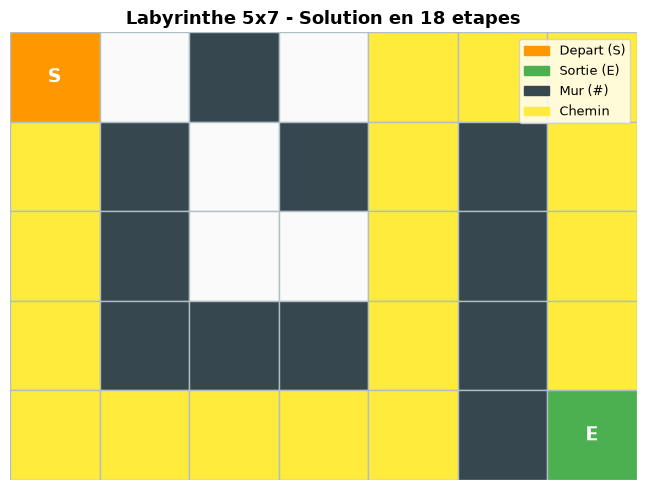

In [19]:
def visualize_maze(problem: MazeProblem, solution_actions: List[str] = None):
    """Visualise le labyrinthe avec optionnellement le chemin solution."""
    fig, ax = plt.subplots(figsize=(max(problem.cols, 6), max(problem.rows, 4)))
    
    # Calculer le chemin solution
    path_cells = set()
    if solution_actions:
        state = problem.initial_state()
        path_cells.add(state)
        for a in solution_actions:
            state = problem.transition(state, a)
            path_cells.add(state)
    
    # Dessiner les cellules
    for r in range(problem.rows):
        for c in range(problem.cols):
            cell = problem.maze[r][c]
            
            if cell == '#':
                color = '#37474F'  # Mur sombre
            elif (r, c) == problem.start_pos:
                color = '#FF9800'  # Depart orange
            elif (r, c) == problem.exit_pos:
                color = '#4CAF50'  # Sortie vert
            elif (r, c) in path_cells:
                color = '#FFEB3B'  # Chemin jaune
            else:
                color = '#FAFAFA'  # Passage
            
            rect = plt.Rectangle((c - 0.5, problem.rows - 1 - r - 0.5), 1, 1,
                                  facecolor=color, edgecolor='#B0BEC5', linewidth=1)
            ax.add_patch(rect)
            
            if cell == 'S':
                ax.text(c, problem.rows - 1 - r, 'S', ha='center', va='center',
                        fontsize=14, fontweight='bold', color='white')
            elif cell == 'E':
                ax.text(c, problem.rows - 1 - r, 'E', ha='center', va='center',
                        fontsize=14, fontweight='bold', color='white')
    
    ax.set_xlim(-0.5, problem.cols - 0.5)
    ax.set_ylim(-0.5, problem.rows - 0.5)
    ax.set_aspect('equal')
    ax.axis('off')
    
    status = f" - Solution en {len(solution_actions)} etapes" if solution_actions else ""
    ax.set_title(f"Labyrinthe {problem.rows}x{problem.cols}{status}",
                 fontsize=13, fontweight='bold')
    
    # Legende
    legend_patches = [
        mpatches.Patch(color='#FF9800', label='Depart (S)'),
        mpatches.Patch(color='#4CAF50', label='Sortie (E)'),
        mpatches.Patch(color='#37474F', label='Mur (#)'),
    ]
    if solution_actions:
        legend_patches.append(mpatches.Patch(color='#FFEB3B', label='Chemin'))
    ax.legend(handles=legend_patches, loc='upper right', fontsize=9)
    
    plt.tight_layout()
    plt.show()


# Afficher le labyrinthe avec la solution
try:
    visualize_maze(maze, solution)
except (NameError, NotImplementedError, TypeError):
    print("Completez la classe MazeProblem pour voir la visualisation du labyrinthe.")

### Interprétation : Labyrinthe comme espace d'états

**Sortie obtenue** :
- les deux cas limites se comportent comme attendu. La sortie voisine est atteinte en 1 étape (`Droite`). Depuis le départ de la sortie emmurée, aucune action n'est applicable (`[]`), et BFS conclut que la sortie est inatteignable ;
- sur la grille 5x7, 24 cases sur 35 sont accessibles, et BFS trouve un chemin de **18 étapes**. Ce chemin descend la colonne de gauche, longe le bas jusqu'à la cinquième colonne, remonte jusqu'à la ligne du haut, puis redescend la colonne de droite jusqu'à la sortie.

La visualisation montre ce chemin en jaune : le mur de la sixième colonne oblige à faire le tour par le haut.

| Propriété | Valeur |
|-----------|--------|
| Taille de la grille | 5x7 |
| Cases accessibles | 24 |
| Facteur de branchement | 1 à 4 selon la position (2 au départ) |
| Coût | Uniforme (1 par déplacement) |
| Plus court chemin | 18 étapes |

**Points clés** :
1. Le labyrinthe est un graphe **implicite** : aucune arête n'est stockée, elles sont calculées par `actions` à partir de la grille.
2. Comme le coût est uniforme, la BFS garantit que 18 étapes est le minimum. Aucun chemin plus court n'existe sur cette grille.
3. Le cas de la sortie emmurée montre que BFS **termine** aussi en l'absence de solution : l'espace est fini, il est épuisé.
4. Ce même modèle représente des problèmes de robotique ou de recherche de chemin dans les jeux vidéo. L'exercice 5 montre ce qui change quand la position ne suffit plus à décrire l'état.

### Exercice 4 : Vérifier l'invariant de parité du taquin

L'exemple guidé divise $n!$ par 2 en invoquant un **invariant de parité**. Vérifiez-le sur le 8-puzzle au lieu de l'admettre.

**Tâche** :
1. Écrire `nombre_inversions(etat)` : le nombre de paires de tuiles, case vide (0) exclue, rangées dans le mauvais ordre quand on lit la grille ligne par ligne. Par exemple, `(2, 1, 3, 4, 5, 6, 7, 8, 0)` a une seule inversion (2 avant 1).
2. Écrire `est_soluble(etat)` : sur une grille de largeur impaire comme celle du 8-puzzle, un état est atteignable depuis le but si et seulement si son nombre d'inversions est pair.
3. Vérifier empiriquement : un parcours en largeur depuis `EightPuzzle.GOAL`, avec les actions de `EightPuzzle`, doit atteindre exactement 181 440 états, et `est_soluble` doit valoir `True` pour chacun d'eux.

**Indices** :
- Un glissement horizontal ne change pas l'ordre de lecture des tuiles.
- Un glissement vertical fait passer une tuile par-dessus deux autres : le nombre d'inversions varie de 0 ou de 2, sa parité ne change donc pas.
- Pour le parcours, reprenez la structure de `bfs_solve` sans test de but : on veut l'ensemble des états visités.

In [20]:
# Exercice 4 : invariant de parite du 8-puzzle

def nombre_inversions(etat: tuple) -> int:
    # TODO etudiant : compter les paires (i < j) de tuiles non nulles telles que etat[i] > etat[j]
    return None  # TODO etudiant

def est_soluble(etat: tuple) -> bool:
    # TODO etudiant : largeur impaire => soluble si et seulement si le nombre d'inversions est pair
    return None  # TODO etudiant

def etats_atteignables(probleme: EightPuzzle, depart: tuple) -> set:
    # TODO etudiant : parcours en largeur depuis 'depart', retourner l'ensemble des etats visites
    return None  # TODO etudiant


# --- Test (decommentez apres avoir complete l'exercice ci-dessus) ---
# print(f"Inversions de (2, 1, 3, 4, 5, 6, 7, 8, 0) : {nombre_inversions((2, 1, 3, 4, 5, 6, 7, 8, 0))}")
# print(f"Etat de depart du carnet soluble ? {est_soluble(puzzle.initial_state())}")
# atteints = etats_atteignables(EightPuzzle(), EightPuzzle.GOAL)
# print(f"Etats atteints depuis le but : {len(atteints):,}")
# print(f"Tous solubles selon la parite : {all(est_soluble(s) for s in atteints)}")
# print(f"(2, 1, 3, 4, 5, 6, 7, 8, 0) atteint ? {(2, 1, 3, 4, 5, 6, 7, 8, 0) in atteints}")

print("Exercice a completer")

Exercice a completer


### Exercice 5 : Labyrinthe à clé — quand l'état doit contenir plus que la position

Ajoutons à la grille une clé `K` et une porte `D` : la porte ne se franchit qu'une fois la clé ramassée. La position ne suffit plus à décrire la situation : il faut aussi savoir si l'on porte la clé.

**Tâche** : compléter `KeyMazeProblem`, sous-classe de `MazeProblem`, dont l'état est `(ligne, colonne, a_la_cle)`.
- `initial_state` : la position du départ, sans la clé
- `actions` : comme `MazeProblem`, mais la case `D` n'est franchissable qu'avec la clé
- `transition` : arriver sur `K` met `a_la_cle` à `True`
- `is_goal` : la position est celle de `E`
- `state_space_size` : le nombre de cases hors murs, multiplié par 2

**Vérification** : sur la grille fournie, BFS doit trouver un chemin de 12 étapes.

**Question** : ce chemin repasse par des cases déjà traversées. Pourquoi BFS l'accepte-t-il ici, alors qu'avec l'état `(ligne, colonne)` de l'exemple guidé ces cases auraient déjà été marquées comme visitées ?

In [21]:
class KeyMazeProblem(MazeProblem):
    """
    Exercice 5 : labyrinthe avec une cle 'K' et une porte 'D'.
    Etat = (ligne, colonne, a_la_cle).
    Le constructeur de MazeProblem (recherche de 'S' et 'E') est reutilise tel quel.
    """

    def initial_state(self):
        # TODO etudiant : partir de self.start_pos, sans la cle
        return None  # TODO etudiant

    def actions(self, state) -> List[str]:
        # TODO etudiant : comme MazeProblem.actions, mais 'D' n'est franchissable qu'avec la cle
        return None  # TODO etudiant

    def transition(self, state, action):
        # TODO etudiant : se deplacer, et ramasser la cle si la case d'arrivee est 'K'
        return None  # TODO etudiant

    def is_goal(self, state) -> bool:
        # TODO etudiant : la position (ligne, colonne) est la sortie
        return None  # TODO etudiant

    def state_space_size(self) -> int:
        # TODO etudiant : cases hors murs x 2 (avec ou sans la cle)
        return None  # TODO etudiant


key_grid = [
    "K.S..",
    "####.",
    "E.D..",
]

# --- Test (decommentez apres avoir complete l'exercice ci-dessus) ---
# km = KeyMazeProblem(key_grid)
# print(f"Etats possibles : {km.state_space_size()}")
# print(f"Actions depuis le depart : {km.actions(km.initial_state())}")
# chemin, final = bfs_solve(km)
# print(f"Solution en {len(chemin)} etapes : {' -> '.join(chemin)}")
# print(f"Etat final : {final}")

print("Exercice a completer")

Exercice a completer


### Exercice 6 : Les cruches d'eau — tous les états ne sont pas atteignables

On dispose d'une cruche A de 3 litres, d'une cruche B de 5 litres et d'un robinet. Les cruches n'ont pas de graduations. Le but est d'obtenir **exactement 4 litres** dans l'une des cruches.

**Tâche** : compléter `WaterJugs`, dont l'état est `(litres_A, litres_B)`.
- `initial_state` : les deux cruches sont vides
- `actions` : parmi « Remplir A », « Remplir B », « Vider A », « Vider B », « Verser A->B », « Verser B->A », ne garder que celles qui changent l'état
- `transition` : un versement s'arrête quand la cruche source est vide ou que la cruche destination est pleine
- `is_goal` : l'une des deux cruches contient `cible` litres
- `state_space_size` : le nombre de contenus possibles, $(c_A + 1) \times (c_B + 1)$

**Vérification** : avec les cruches de 3 et 5 litres, `state_space_size` vaut 24 et BFS doit trouver une solution en 6 actions.

**Question** : avec des cruches de 2 et 4 litres et une cible de 3 litres, BFS ne trouve aucune solution. Pourquoi ? Quelles quantités peuvent apparaître dans une cruche, quelles que soient les actions choisies ?

In [22]:
class WaterJugs(SearchProblem):
    """
    Exercice 6 : deux cruches de capacites cap_a et cap_b litres, et un robinet.
    Etat = (litres_A, litres_B). But : une cruche contient exactement `cible` litres.
    """

    ACTIONS = ["Remplir A", "Remplir B", "Vider A", "Vider B", "Verser A->B", "Verser B->A"]

    def __init__(self, cap_a: int = 3, cap_b: int = 5, cible: int = 4):
        self.cap_a, self.cap_b, self.cible = cap_a, cap_b, cible

    def initial_state(self):
        # TODO etudiant : les deux cruches sont vides
        return None  # TODO etudiant

    def actions(self, state) -> List[str]:
        # TODO etudiant : garder les actions de ACTIONS dont la transition change l'etat
        return None  # TODO etudiant

    def transition(self, state, action):
        # TODO etudiant : remplir, vider, ou verser jusqu'a vider la source ou remplir la destination
        return None  # TODO etudiant

    def is_goal(self, state) -> bool:
        # TODO etudiant : l'une des deux cruches contient self.cible litres
        return None  # TODO etudiant

    def state_space_size(self) -> int:
        # TODO etudiant : (cap_a + 1) x (cap_b + 1) contenus possibles
        return None  # TODO etudiant


# --- Test (decommentez apres avoir complete l'exercice ci-dessus) ---
# cruches = WaterJugs()
# print(f"Contenus possibles : {cruches.state_space_size()}")
# print(f"Actions depuis {cruches.initial_state()} : {cruches.actions(cruches.initial_state())}")
# chemin, final = bfs_solve(cruches)
# print(f"Solution en {len(chemin)} actions : {' -> '.join(chemin)}")
# print(f"Etat final : {final}")
# chemin_2_4, _ = bfs_solve(WaterJugs(cap_a=2, cap_b=4, cible=3))
# print(f"Cruches de 2 et 4 litres, cible 3 : {chemin_2_4}")

print("Exercice a completer")

Exercice a completer


## 8. Resume

### Concepts cles

| Concept | Definition |
|---------|------------|
| **Espace d'etats** $S$ | Ensemble de toutes les configurations possibles du problème |
| **Etat initial** $s_0$ | Configuration de depart |
| **Actions** $A(s)$ | Opérations applicables dans un etat |
| **Transition** $T(s,a)$ | Fonction qui produit le nouvel etat |
| **Test de but** $G(s)$ | Determine si un etat est une solution |
| **Fonction de cout** $c(s,a,s')$ | Cout associe a une transition |
| **Solution** | Chemin de $s_0$ a un etat but |
| **Solution optimale** | Solution de cout minimal |

### Problemes etudies

| Problème | Taille $\lvert S\rvert$ | Cout | Difficulte principale |
|----------|-------------|------|-----------------------|
| Aspirateur | 8 | Uniforme | Trivial, sert de modèle pedagogique |
| 8-Puzzle | 181 440 | Uniforme | Taille de l'espace, profondeur des solutions |
| Itineraire | Variable | Distances | Couts non uniformes, necessite UCS ou A* |
| Missionnaires | 20 états valides | Uniforme | Contraintes de validite des etats |
| Labyrinthe | 24 (grille 5x7) | Uniforme | Structure implicite du graphe |
| Labyrinthe à clé | 2 x cases hors murs | Uniforme | L'etat doit memoriser la cle, pas seulement la position |
| Cruches d'eau | 24 (cruches de 3 et 5 L) | Uniforme | Tous les contenus ne sont pas atteignables |

### Ce qu'il faut retenir

1. **Tout problème de planification** peut se formaliser comme un problème de recherche dans un espace d'etats
2. **La taille de l'espace** determine la complexite computationnelle
3. **Le type de cout** (uniforme ou non) determine le choix de l'algorithme
4. **Les proprietes** (observable, déterministe, discret) conditionnent les algorithmes applicables


## Resume et perspectives

Ce notebook a pose les fondements de la recherche dans les espaces d'etats : la formalisation en 5-tuple $(S, s_0, A, T, G)$, la modelisation de problemes concrets (aspirateur, taquin, itineraire), et l'analyse des proprietes qui influencent le choix algorithmique. La distinction entre cout uniforme et cout variable, illustree par l'exemple de l'itineraire, sera determinante dans les prochains notebooks.

**Le passage au [notebook Search-02-Uninformed](Search-02-Uninformed.ipynb)** aborde les algorithmes systématiques -- BFS, DFS, UCS -- qui exploitent uniquement la structure du graphe d'etats, sans connaissance spécifique du problème, pour garantir completude et optimalite selon les conditions.



### References academiques

- Newell, A. & Simon, H.A. (1961). GPS, A Program That Simulates Human Thought. In R. Gunbaum & E. Paul (eds.), Thinking Machines. Basic Books.
- Amarel, S. (1968). On Representations of Problems of Reasoning About Actions. Machine Intelligence 3:131-171.
- Russell, S. & Norvig, P. (2020). Artificial Intelligence: A Modern Approach (4th ed.). Pearson.



## À retenir

1. Un problème de recherche se formalise en **5-tuple $(S, s_0, A, T, G)$** — plus une fonction de coût optionnelle. La classe abstraite `SearchProblem` en est la traduction directe, instanciée trois fois dans ce carnet (aspirateur, taquin, itinéraire).
2. Monde de l'aspirateur : **8 états**, solution optimale *Aspirer, Droite, Aspirer* en **3 coups** — et la sortie le montre : les actions disponibles **dépendent de l'état** (« Gauche » n'existe pas depuis la pièce gauche).
3. Taquin : $9!/2 = 181\,440$ états accessibles — la **moitié** des permutations seulement — pour un facteur de branchement moyen de **2,67** (2 au coin, 4 au centre). L'exemple guidé de la section 7 montre l'explosion factorielle : au 15-puzzle, $\approx 10^{13}$ états accessibles referment la porte de l'énumération exhaustive.
4. Itinéraire : **nombre d'étapes n'est pas le coût** — via Paris (2 étapes, 1 075 km) bat via le sud (5 étapes, 1 465 km). Dijkstra (networkx) **confirme** l'optimum à 1 075 km, et la centralité d'intermédiarité désigne **Lyon et Marseille (0,422)** — devant Paris (0,267) — comme points de passage structurels du réseau.
5. Le **type de coût décide de l'algorithme** : uniforme (aspirateur, taquin) → BFS suffit ; variable (distances) → UCS ou A* deviennent nécessaires.

## Vérifiez votre compréhension

1. Dans l'état initial `(G, sale, sale)`, pourquoi l'action « Gauche » n'est-elle pas proposée ?
2. Le taquin 3×3 compte $9! = 362\,880$ permutations. Pourquoi `EightPuzzle.state_space_size()` annonce-t-il 181 440 ?
3. Entre via Paris (2 étapes, 1 075 km) et via le sud (5 étapes, 1 465 km), lequel BFS retourne-t-il, et lequel est optimal en distance ?

<details><summary>Réponses</summary>

1. `actions(s)` dépend de l'état `s` : l'aspirateur est déjà dans la pièce gauche, seuls *Aspirer* et *Droite* sont applicables — la sortie de la première cellule aspirateur le montre (`['Aspirer', 'Droite']`).
2. Seule la **moitié des permutations est atteignable** par glissements successifs (argument de parité) : l'espace réellement explorable vaut $9!/2 = 181\,440$.
3. BFS minimise les **étapes** : il retourne via Paris. Il se trouve qu'il est aussi optimal en km — mais c'est le parcours systématique de Dijkstra qui le **prouve** (1 075 km), pas la comparaison à la main. Sur le graphe différent du jumeau C#, cette même vérification **infirme** le chemin désigné à la main.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Search-02-Uninformed](Search-02-Uninformed.ipynb) — les algorithmes aveugles (BFS, DFS, UCS, IDDFS) qui exploitent la structure posée ici.
- **Jumeau C#** : [Search-01-StateSpace-CSharp.ipynb](Search-01-StateSpace-CSharp.ipynb) — même 5-tuple sous .NET 9, sur un graphe routier différent (13 villes) où le moteur de parcours infirme le vainqueur choisi à la main.
- **Carnet voisin d'une autre série** : [Sudoku-01-Backtracking-Python](../../Sudoku/Sudoku-01-Backtracking-Python.ipynb) — une grille Sudoku comme espace d'états implicite, explorée par retour arrière.
- **Lecture** : Russell & Norvig, *Artificial Intelligence: A Modern Approach* (4e éd.), chap. 3.1-3.3 ; Amarel (1968), *On Representations of Problems of Reasoning About Actions*.

***

**Navigation** : [Index](../README.md) | [Suivant >>](Search-02-Uninformed.ipynb)